# 2025 & 2026 Coral Heat Stress Predictions

Loads the fold-5 XGBoost model from the experiment specified by `EXP_NAME` and
evaluates it on 2025 and 2026 summer data for all three reef sites.
Fold-5 reference performance (2017–2024) is reprinted for comparison.

**Author:** Marybeth Arcodia

**Usage:** Set `EXP_NAME` in the Configuration cell, then run all cells top-to-bottom.
Requires that `stress_predictions_original.ipynb` has been run for the chosen experiment.

In [1]:
import sys
import json
sys.path.insert(0, '../src')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import warnings
from pathlib import Path
from xgboost import XGBClassifier

import preprocess as preprocess_module
from data_split import create_labels_and_features
import train_test_model

warnings.filterwarnings('ignore')
np.set_printoptions(threshold=np.inf)

/opt/homebrew/anaconda3/envs/env-coral-stress-predict/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Configuration

In [2]:
# ── Experiment to load models from — change this to switch experiments ────────
EXP_NAME = 'exp004'

# ── Run identifier — update each time you run with fresh data ─────────────────
# Used as a suffix on the output folder so previous runs are never overwritten.
# Convention: 'wkNN' where NN is the ISO week of the most recent CSV data.
RUN_THROUGH_WEEK = 'wk27'

# ── Sites ─────────────────────────────────────────────────────────────────────
SITES_TO_RUN = ['sombrero', 'molasses', 'sk']

# ── Paths ─────────────────────────────────────────────────────────────────────
DATA_DIR   = Path('../Data')
OUTPUT_DIR = Path('../output')
MODELS_EXP = EXP_NAME
OUT_DIR    = OUTPUT_DIR / EXP_NAME / f'predictions_2025_2026_{RUN_THROUGH_WEEK}'

# ── Model fold ────────────────────────────────────────────────────────────────
# For multi-fold experiments (exp001–003): set MODEL_FOLD to the fold number (e.g. 5).
# For no-fold experiments  (exp004+):      set MODEL_FOLD = None
#   → loads {site}_xgb_nofolds.model instead of {site}_xgb_fold_N.model
MODEL_FOLD = None 

# ── Evaluation years ──────────────────────────────────────────────────────────
# exp001–003 (fold model):  EVAL_YEARS = [2025, 2026]
# exp004     (no-fold):     EVAL_YEARS = [2024, 2025, 2026]
# Note: 2026 has only 2 weeks of data and no ground truth yet.
EVAL_YEARS  = [2024, 2025, 2026]
FOLD5_YEARS = list(range(2017, 2025))   # Reference period — only used when MODEL_FOLD is not None

# ── Data file ─────────────────────────────────────────────────────────────────
DATA_FILENAME_TEMPLATE = '{site}_preds.csv'

# ── Prediction parameters (must match stress_predictions_original.ipynb) ──────
STRESS_THRESHOLD = 4
PREDICTION_SPAN  = 6
VAL_NO_ONSET     = PREDICTION_SPAN + 1   # = 7
SUMMER_START     = 21
SUMMER_END       = 40
WEEKS_PER_YEAR   = SUMMER_END - SUMMER_START + 1   # = 20
TOLERANCE        = 1

COLUMNS_TO_KEEP = [
    'week', 'meanDhw', 'meanHs', 'weeks_until_onset',
    'meanDhw_lag_1', 'meanDhw_lag_2', 'meanSsta',
    'airTempInter', 'zonalWindInter', 'oniInter',
    'loop_curr_sst',
    # 'dswrf',  # excluded in exp002+
]

SITE_DISPLAY_NAMES = {'sombrero': 'Sombrero', 'sk': 'Sand Key', 'molasses': 'Molasses'}

fold_label = 'no-fold' if MODEL_FOLD is None else f'fold {MODEL_FOLD}'
print(f'Experiment:      {EXP_NAME}')
print(f'Models from:     {OUTPUT_DIR / MODELS_EXP}  ({fold_label})')
print(f'Outputs to:      {OUT_DIR}')
print(f'Eval years:      {EVAL_YEARS}')
if MODEL_FOLD is not None:
    print(f'Fold ref:        {FOLD5_YEARS[0]}–2024')


Experiment:      exp004
Models from:     ../output/exp004  (no-fold)
Outputs to:      ../output/exp004/predictions_2025_2026_wk27
Eval years:      [2024, 2025, 2026]


## Preprocessing & Prediction

Runs the same pipeline as `stress_predictions_original.ipynb` with no row cutoff
so that 2025 and 2026 data are included.  The `year` column is saved before
`select_columns` drops it, then used to split rows by year.

In [3]:
all_results = {}   # all_results[reef_location]['years'][year]

for reef_location in SITES_TO_RUN:
    site_name = SITE_DISPLAY_NAMES.get(reef_location, reef_location.capitalize())

    # ── Model path: fold-based or no-fold ─────────────────────────────────────
    if MODEL_FOLD is None:
        model_file = f'{reef_location}_xgb_nofolds.model'
    else:
        model_file = f'{reef_location}_xgb_fold_{MODEL_FOLD}.model'
    model_path = OUTPUT_DIR / MODELS_EXP / reef_location / 'models' / model_file

    print()
    print('=' * 60)
    print(f'Site: {site_name}')

    # ── Preprocess all years (no cutoff) ──────────────────────────────────────
    preprocessor = preprocess_module.CoralBleachingPreprocessor(
        str(DATA_DIR) + '/',
        reef_location,
        STRESS_THRESHOLD,
        VAL_NO_ONSET,
        PREDICTION_SPAN,
        WEEKS_PER_YEAR,
    )
    preprocessor.load_data(DATA_FILENAME_TEMPLATE.format(site=reef_location))
    preprocessor.preprocess_time_variables()
    preprocessor.calculate_weeks_until_onset(PREDICTION_SPAN)
    preprocessor.add_lag_features({'meanDhw': [1, 2]})

    year_series = preprocessor.data['year'].copy()
    preprocessor.select_columns(COLUMNS_TO_KEEP)
    preprocessor.drop_missing_values()
    preprocessor.filter_summer_weeks(SUMMER_START, SUMMER_END)

    processed_data = preprocessor.data.copy()
    processed_data['year'] = year_series.loc[processed_data.index].values

    # ── Load model ────────────────────────────────────────────────────────────
    if not model_path.exists():
        nb = 'stress_predictions_nofolds.ipynb' if MODEL_FOLD is None else 'stress_predictions_original.ipynb'
        print(f'  ERROR: model not found: {model_path}')
        print(f'  Run {nb} with EXP_NAME="{MODELS_EXP}" first.')
        continue
    xgb_model = XGBClassifier()
    xgb_model.load_model(str(model_path))
    print(f'  Model loaded ({model_file})')

    all_results[reef_location] = {'site_name': site_name, 'years': {}}

    # ── Fold reference metrics (only for fold-based models) ───────────────────
    if MODEL_FOLD is not None:
        data_fold5 = processed_data[processed_data['year'].isin(FOLD5_YEARS)].drop(columns=['year'])
        labels_f5, features_f5 = create_labels_and_features(data_fold5)
        preds_f5   = np.round(xgb_model.predict(features_f5).astype(float), 0)
        masked_f5  = train_test_model.apply_onset_mask_single(labels_f5, preds_f5, WEEKS_PER_YEAR)
        valid_f5   = ~np.isnan(masked_f5)
        cutoff_f5  = np.repeat(VAL_NO_ONSET, len(labels_f5))
        hit_f5  = valid_f5 & (labels_f5 < VAL_NO_ONSET) & (np.abs(masked_f5 - labels_f5) <= TOLERANCE)
        miss_f5 = valid_f5 & (labels_f5 < VAL_NO_ONSET) & (np.abs(masked_f5 - labels_f5) > TOLERANCE)
        fa_f5   = valid_f5 & (labels_f5 == VAL_NO_ONSET) & (masked_f5 < cutoff_f5)
        tno_f5  = valid_f5 & (labels_f5 == VAL_NO_ONSET) & (masked_f5 >= cutoff_f5)
        n_h = int(np.sum(hit_f5)); n_m = int(np.sum(miss_f5))
        n_f = int(np.sum(fa_f5));  n_t = int(np.sum(tno_f5))
        pr_f5 = n_h / (n_h + n_f) if (n_h + n_f) > 0 else 0.0
        re_f5 = n_h / (n_h + n_m) if (n_h + n_m) > 0 else 0.0
        f1_f5 = 2 * pr_f5 * re_f5 / (pr_f5 + re_f5) if (pr_f5 + re_f5) > 0 else 0.0
        all_results[reef_location]['fold5_ref'] = {
            'labels': labels_f5, 'preds': preds_f5,
            'hit': n_h, 'miss': n_m, 'fa': n_f, 'tno': n_t, 'f1': f1_f5,
        }
        print(f'  Fold{MODEL_FOLD} ref ({FOLD5_YEARS[0]}-{FOLD5_YEARS[-1]}): '
              f'Hit={n_h} Miss={n_m} FA={n_f} TNO={n_t}  F1={f1_f5:.3f}')

    # ── Predict each eval year ────────────────────────────────────────────────
    for eval_year in EVAL_YEARS:
        data_yr = processed_data[processed_data['year'] == eval_year].drop(columns=['year'])
        if len(data_yr) == 0:
            print(f'  WARNING: no {eval_year} summer data for {reef_location} — skipping.')
            continue

        labels_yr, features_yr = create_labels_and_features(data_yr)
        preds_raw_yr  = np.round(xgb_model.predict(features_yr).astype(float), 0)

        # Predicted class probability: softmax applied to summed tree scores (XGBoost boosting)
        proba_matrix_yr = xgb_model.predict_proba(features_yr)   # (n_weeks, n_classes)
        pred_proba_yr = np.array([
            proba_matrix_yr[i, int(preds_raw_yr[i])]
            for i in range(len(preds_raw_yr))
        ])

        masked_preds_yr = train_test_model.apply_onset_mask_single(
            labels_yr, preds_raw_yr, WEEKS_PER_YEAR
        )

        valid_yr  = ~np.isnan(masked_preds_yr)
        cutoff_yr = np.repeat(VAL_NO_ONSET, len(labels_yr))
        hit  = valid_yr & (labels_yr < VAL_NO_ONSET) & (np.abs(masked_preds_yr - labels_yr) <= TOLERANCE)
        miss = valid_yr & (labels_yr < VAL_NO_ONSET) & (np.abs(masked_preds_yr - labels_yr) > TOLERANCE)
        fa   = valid_yr & (labels_yr == VAL_NO_ONSET) & (masked_preds_yr < cutoff_yr)
        tno  = valid_yr & (labels_yr == VAL_NO_ONSET) & (masked_preds_yr >= cutoff_yr)
        n_hit  = int(np.sum(hit));  n_miss = int(np.sum(miss))
        n_fa   = int(np.sum(fa));   n_tno  = int(np.sum(tno))
        precision = n_hit / (n_hit + n_fa)   if (n_hit + n_fa)   > 0 else float('nan')
        recall    = n_hit / (n_hit + n_miss) if (n_hit + n_miss) > 0 else float('nan')
        f1 = (2 * precision * recall / (precision + recall)
              if np.isfinite(precision) and np.isfinite(recall) and (precision + recall) > 0
              else float('nan'))
        fa_rate   = n_fa  / (n_fa  + n_tno)  if (n_fa  + n_tno)  > 0 else float('nan')
        onset_acc = n_hit / (n_hit + n_miss) if (n_hit + n_miss) > 0 else float('nan')

        onset_idx   = np.where(labels_yr == 0)[0]
        onset_label = (f'onset at summer week {onset_idx[0]+1}'
                       if len(onset_idx) > 0 else 'no onset')
        f1_disp = f'{f1:.3f}' if np.isfinite(f1) else 'N/A'
        print(f'  {eval_year}: {onset_label}  |  weeks={len(labels_yr)}  '
              f'Hit={n_hit} Miss={n_miss} FA={n_fa} TNO={n_tno}  F1={f1_disp}')

        all_results[reef_location]['years'][eval_year] = {
            'labels':       labels_yr,
            'preds_raw':    preds_raw_yr,
            'masked_preds': masked_preds_yr,
            'pred_proba':   pred_proba_yr,
            'n_weeks':      len(labels_yr),
            'metrics': {
                'hit': n_hit, 'miss': n_miss, 'fa': n_fa, 'tno': n_tno,
                'f1': f1, 'fa_rate': fa_rate, 'onset_acc': onset_acc,
            },
        }

print()
print('Done. Run the cells below to view printed output, plots, and summary table.')


Site: Sombrero
Data loaded from ../Data/sombrero_preds.csv
Data filtered to weeks 21–40.
  Model loaded (sombrero_xgb_nofolds.model)
  2024: onset at summer week 13  |  weeks=20  Hit=7 Miss=0 FA=3 TNO=3  F1=0.824
  2025: onset at summer week 14  |  weeks=20  Hit=6 Miss=1 FA=0 TNO=7  F1=0.923
  2026: no onset  |  weeks=7  Hit=0 Miss=0 FA=3 TNO=4  F1=N/A

Site: Molasses
Data loaded from ../Data/molasses_preds.csv
Data filtered to weeks 21–40.
  Model loaded (molasses_xgb_nofolds.model)
  2024: onset at summer week 14  |  weeks=20  Hit=3 Miss=4 FA=0 TNO=7  F1=0.600
  2025: onset at summer week 14  |  weeks=20  Hit=3 Miss=4 FA=0 TNO=7  F1=0.600
  2026: no onset  |  weeks=7  Hit=0 Miss=0 FA=0 TNO=7  F1=N/A

Site: Sand Key
Data loaded from ../Data/sk_preds.csv
Data filtered to weeks 21–40.
  Model loaded (sk_xgb_nofolds.model)
  2024: onset at summer week 12  |  weeks=20  Hit=4 Miss=3 FA=0 TNO=5  F1=0.727
  2025: onset at summer week 14  |  weeks=20  Hit=7 Miss=0 FA=1 TNO=6  F1=0.933
  2026

## Printed Predictions

Fold-5 reference (2017–2024) followed by each evaluation year.

In [4]:
if not all_results:
    print('Run the prediction cell first.')
else:
    for reef_location in SITES_TO_RUN:
        if reef_location not in all_results:
            continue

        res       = all_results[reef_location]
        site_name = res['site_name']
        fv        = res.get('fold5_ref')

        if fv is not None:
            print()
            print('=' * 60)
            print(f'{site_name} — Fold {MODEL_FOLD} reference ({FOLD5_YEARS[0]}–{FOLD5_YEARS[-1]})')
            print('=' * 60)
            print('TRUTH')
            print(train_test_model.format_week_delimited(fv['labels'], WEEKS_PER_YEAR))
            print('XGB PREDICTIONS')
            print(train_test_model.format_week_delimited(fv['preds'], WEEKS_PER_YEAR))

        for eval_year in EVAL_YEARS:
            if eval_year not in res['years']:
                continue
            yr         = res['years'][eval_year]
            is_partial = yr['n_weeks'] < WEEKS_PER_YEAR
            print()
            print(f'{site_name} — {eval_year}')
            print('-' * 40)
            if not is_partial:
                print('TRUTH')
                print(train_test_model.format_week_delimited(yr['labels'], WEEKS_PER_YEAR))
            else:
                print(f'(season in progress through {RUN_THROUGH_WEEK} — truth not yet available)')
            print('XGB PREDICTIONS')
            print(train_test_model.format_week_delimited(yr['preds_raw'], WEEKS_PER_YEAR))



Sombrero — 2024
----------------------------------------
TRUTH
 7  7  7  7  7  7  6  5  4  3  2  1  0  0  0  0  0  0  0  0
XGB PREDICTIONS
 7  4  7  6  7  6  7  6  4  3  2  1  0  0  0  0  0  0  0  0

Sombrero — 2025
----------------------------------------
TRUTH
 7  7  7  7  7  7  7  6  5  4  3  2  1  0  0  0  0  0  0  0
XGB PREDICTIONS
 7  7  7  7  7  7  7  6  7  4  3  2  2  0  0  0  0  0  0  0

Sombrero — 2026
----------------------------------------
(season in progress through wk27 — truth not yet available)
XGB PREDICTIONS
 7  7  7  7  4  3  2

Molasses — 2024
----------------------------------------
TRUTH
 7  7  7  7  7  7  7  6  5  4  3  2  1  0  0  0  0  0  0  0
XGB PREDICTIONS
 7  7  7  7  7  7  7  7  7  7  7  7  1  0  0  0  0  0  0  0

Molasses — 2025
----------------------------------------
TRUTH
 7  7  7  7  7  7  7  6  5  4  3  2  1  0  0  0  0  0  0  0
XGB PREDICTIONS
 7  7  7  7  7  7  7  7  7  7  7  7  1  0  0  0  0  0  0  0

Molasses — 2026
----------------------------

## Plots

Separate figure for each evaluation year.  Each figure shows all three sites
(rows) with a prediction timeline (left) and outcome bar chart (right).
Plots are saved to `../output/{OUT_EXP}/{year}/plots/`.

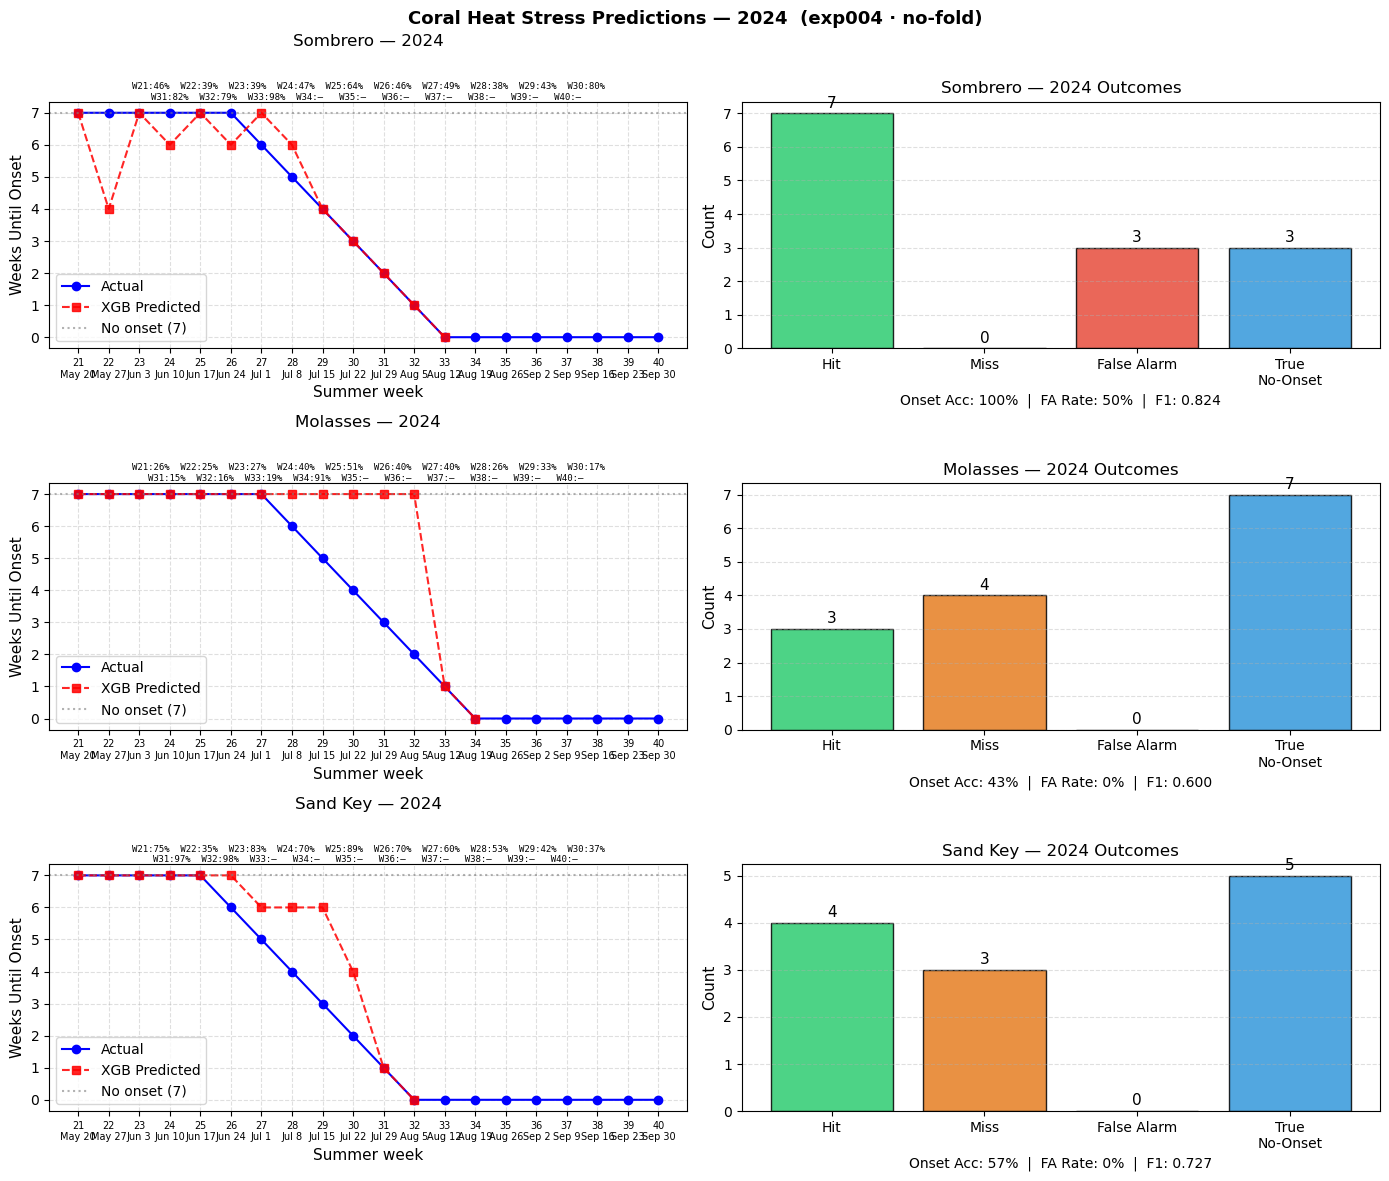

Saved: ../output/exp004/predictions_2025_2026_wk27/predictions_2024.png


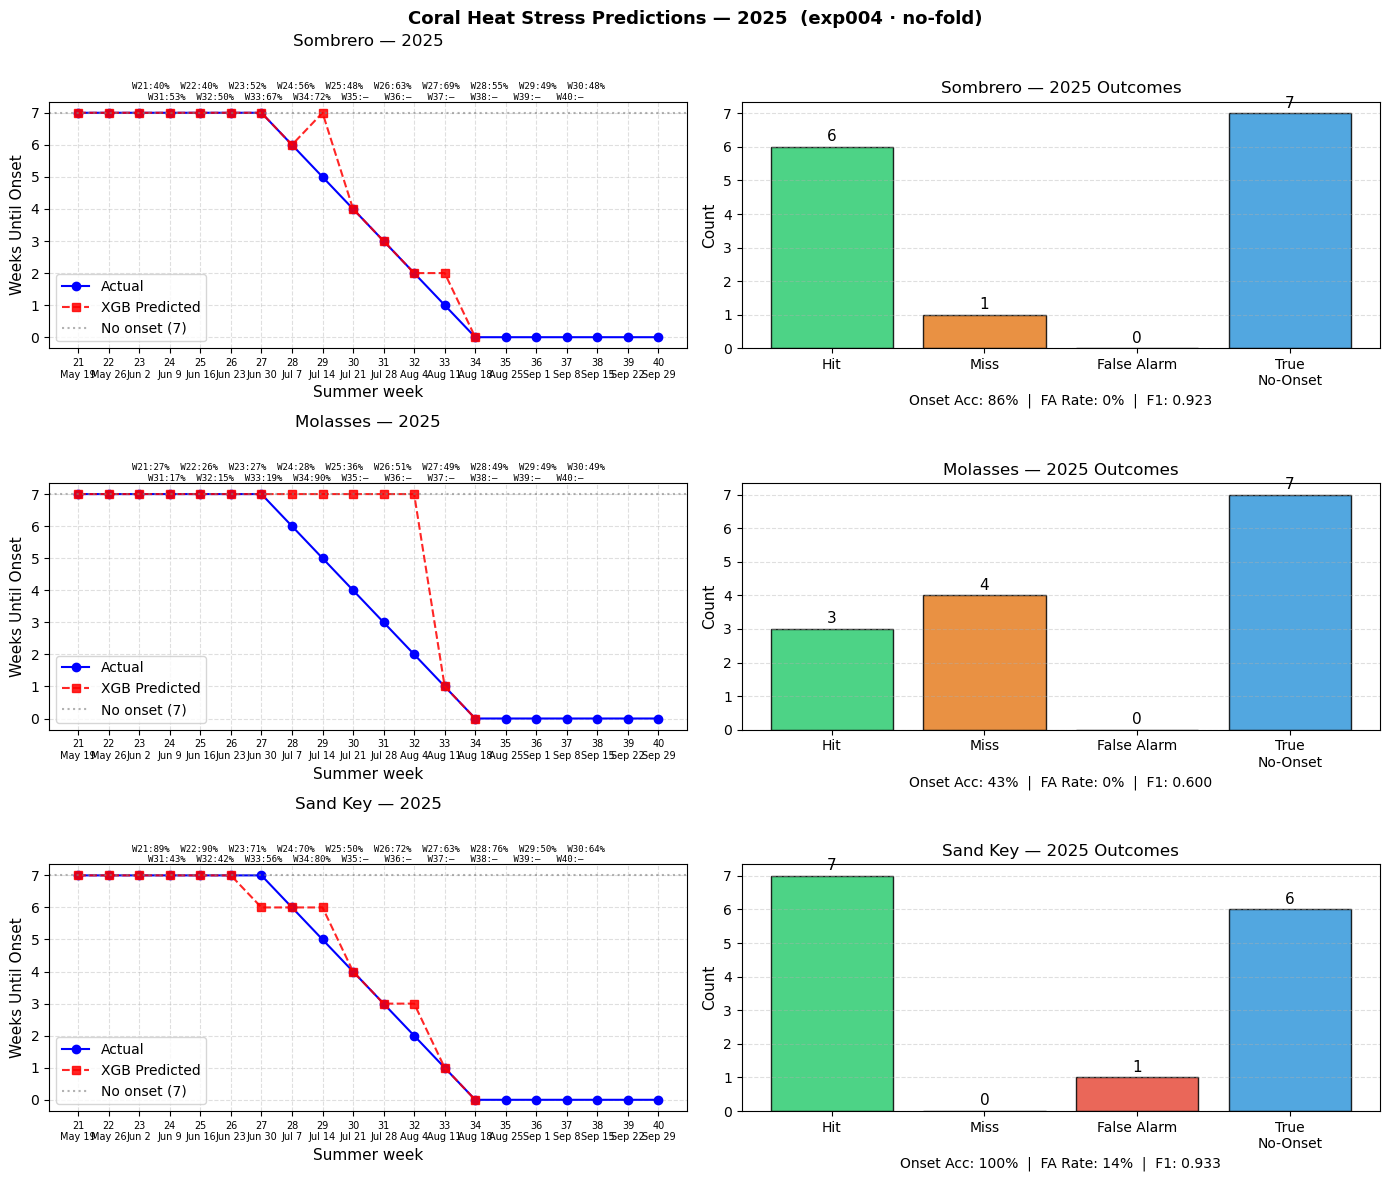

Saved: ../output/exp004/predictions_2025_2026_wk27/predictions_2025.png


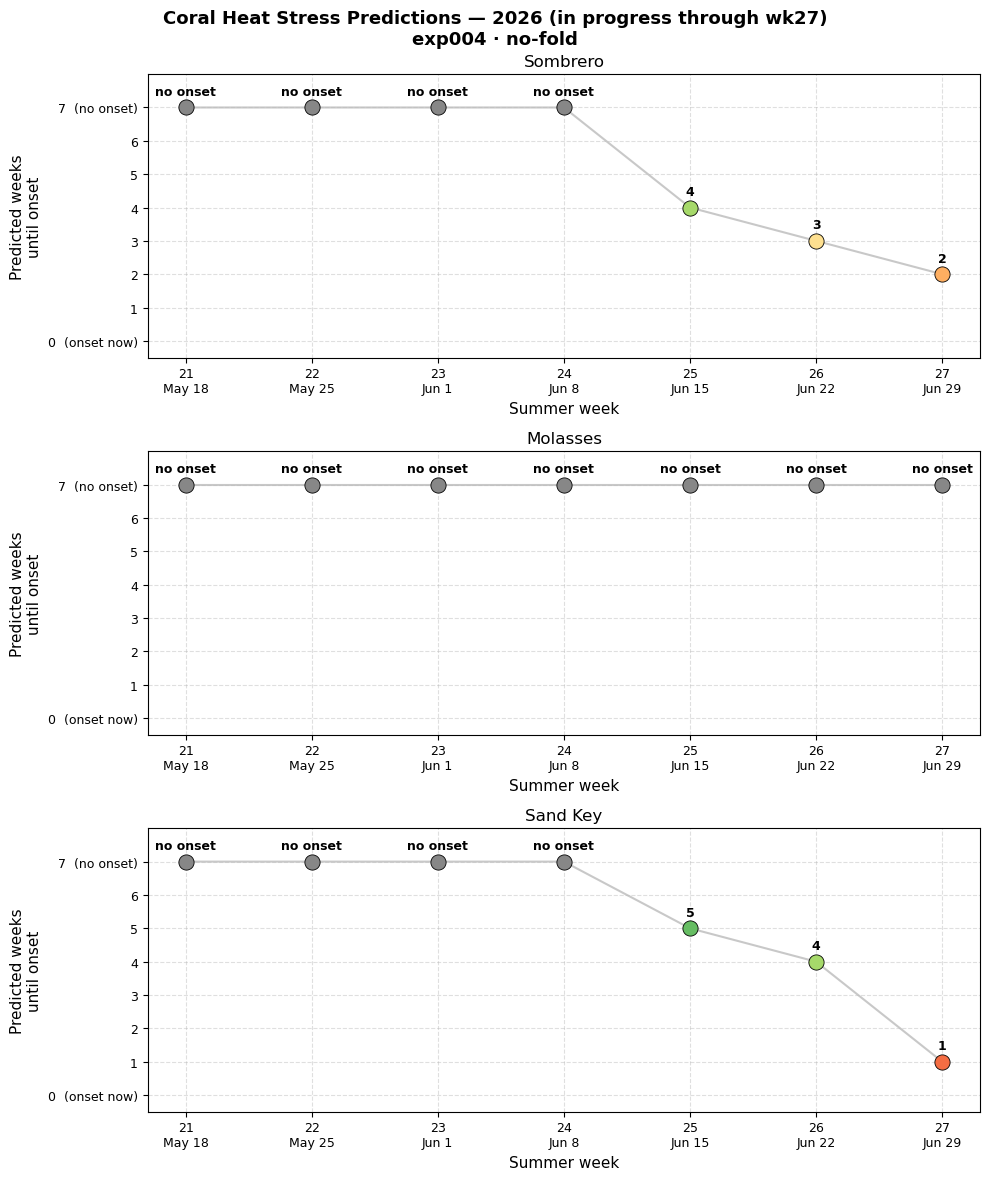

Saved: ../output/exp004/predictions_2025_2026_wk27/predictions_2026.png


In [5]:
if not all_results:
    print('Run the prediction cell first.')
else:
    from datetime import date as _date

    PRED_COLORS = {
        0: '#d73027',  # red — onset now
        1: '#f46d43',  # orange-red
        2: '#fdae61',  # orange
        3: '#fee090',  # yellow
        4: '#a6d96a',  # light green
        5: '#66bd63',  # green
        6: '#1a9850',  # dark green
        7: '#878787',  # gray — no onset
    }

    for eval_year in EVAL_YEARS:
        sites_with_data = [s for s in SITES_TO_RUN
                           if s in all_results and eval_year in all_results[s]['years']]
        if not sites_with_data:
            print(f'No data for {eval_year} — skipping plot.')
            continue

        sample_yr  = all_results[sites_with_data[0]]['years'][eval_year]
        is_partial = sample_yr['n_weeks'] < WEEKS_PER_YEAR
        n_sites    = len(sites_with_data)
        fold_label = 'no-fold' if MODEL_FOLD is None else f'fold {MODEL_FOLD}'

        if is_partial:
            # ── Prediction-only layout for in-progress year ───────────────────
            fig, axes = plt.subplots(n_sites, 1, figsize=(10, 4 * n_sites))
            if n_sites == 1:
                axes = [axes]
            fig.suptitle(
                f'Coral Heat Stress Predictions — {eval_year}'
                f' (in progress through {RUN_THROUGH_WEEK})'
                f'\n{EXP_NAME} · {fold_label}',
                fontsize=13, fontweight='bold',
            )

            for row, reef_location in enumerate(sites_with_data):
                res       = all_results[reef_location]
                site_name = res['site_name']
                yr        = res['years'][eval_year]
                masked    = yr['masked_preds']
                n_weeks   = yr['n_weeks']
                weeks     = np.arange(SUMMER_START, SUMMER_START + n_weeks)

                week_dates = [
                    _date.fromisocalendar(eval_year, int(w), 1).strftime('%b %-d')
                    for w in weeks
                ]

                ax = axes[row]

                # Thin connecting line through non-NaN predictions
                valid = ~np.isnan(masked)
                if valid.any():
                    ax.plot(weeks[valid], masked[valid], '-',
                            color='#bbbbbb', linewidth=1.5, alpha=0.8, zorder=2)

                # Colored scatter markers
                for w, p in zip(weeks, masked):
                    if not np.isnan(p):
                        c = PRED_COLORS.get(int(p), '#888888')
                        ax.scatter(w, p, color=c, s=120, zorder=5,
                                   edgecolors='black', linewidths=0.6)

                # Value annotations above each point
                for w, p in zip(weeks, masked):
                    if not np.isnan(p):
                        lbl = 'onset' if int(p) == 0 else ('no onset' if int(p) == 7 else str(int(p)))
                        ax.annotate(lbl, (w, p), textcoords='offset points', xytext=(0, 9),
                                    ha='center', fontsize=9, fontweight='bold')

                ax.set_title(site_name, fontsize=12)
                ax.set_yticks(range(8))
                ax.set_yticklabels(
                    ['0  (onset now)', '1', '2', '3', '4', '5', '6', '7  (no onset)'],
                    fontsize=9,
                )
                ax.set_ylabel('Predicted weeks\nuntil onset', fontsize=11)
                ax.set_xticks(weeks)
                ax.set_xticklabels(
                    [f'{w}\n{d}' for w, d in zip(weeks, week_dates)],
                    fontsize=9,
                )
                ax.set_xlabel('Summer week', fontsize=11)
                ax.set_ylim(-0.5, 8.0)
                ax.grid(True, linestyle='--', alpha=0.4)

        else:
            # ── Standard timeline + bar chart layout for complete years ────────
            fig, axes = plt.subplots(n_sites, 2, figsize=(14, 4 * n_sites))
            if n_sites == 1:
                axes = axes[np.newaxis, :]
            fig.suptitle(
                f'Coral Heat Stress Predictions — {eval_year}'
                f'  ({EXP_NAME} · {fold_label})',
                fontsize=13, fontweight='bold',
            )

            for row, reef_location in enumerate(sites_with_data):
                res        = all_results[reef_location]
                site_name  = res['site_name']
                yr         = res['years'][eval_year]
                labels     = yr['labels']
                masked     = yr['masked_preds']
                pred_proba = yr['pred_proba']
                m          = yr['metrics']
                n_weeks    = yr['n_weeks']
                weeks      = np.arange(SUMMER_START, SUMMER_START + n_weeks)

                week_dates = [
                    _date.fromisocalendar(eval_year, int(w), 1).strftime('%b %-d')
                    for w in weeks
                ]

                # Per-week probability string
                prob_parts = []
                for i in range(n_weeks):
                    if np.isnan(masked[i]):
                        prob_parts.append(f'W{weeks[i]}:— ')
                    else:
                        prob_parts.append(f'W{weeks[i]}:{pred_proba[i]*100:.0f}%')
                n_half = (n_weeks + 1) // 2
                line1 = '  '.join(prob_parts[:n_half])
                line2 = '  '.join(prob_parts[n_half:])
                prob_str = line1 + ('\n' + line2 if line2 else '')
                n_prob_lines = 2 if line2 else 1

                # Timeline
                ax = axes[row, 0]
                ax.plot(weeks, labels, 'bo-', label='Actual', markersize=6, linewidth=1.5)
                valid = ~np.isnan(masked)
                ax.plot(weeks[valid], masked[valid], 'rs--', label='XGB Predicted',
                        markersize=6, linewidth=1.5, alpha=0.85)
                ax.axhline(y=VAL_NO_ONSET, color='gray', linestyle=':', alpha=0.6,
                           label=f'No onset ({VAL_NO_ONSET})')
                ax.set_xlabel('Summer week', fontsize=11)
                ax.set_ylabel('Weeks Until Onset', fontsize=11)
                title_pad = 14 + 13 * n_prob_lines
                ax.set_title(f'{site_name} — {eval_year}', fontsize=12, pad=title_pad)
                ax.text(0.5, 1.0, prob_str, transform=ax.transAxes, fontsize=6.5,
                        ha='center', va='bottom', family='monospace', clip_on=False)
                ax.set_xticks(weeks)
                ax.set_xticklabels(
                    [f'{w}\n{d}' for w, d in zip(weeks, week_dates)],
                    fontsize=7,
                )
                ax.legend(fontsize=10)
                ax.grid(True, linestyle='--', alpha=0.4)

                # Bar chart
                ax2 = axes[row, 1]
                counts = [m['hit'], m['miss'], m['fa'], m['tno']]
                bar_colors = ['#2ecc71', '#e67e22', '#e74c3c', '#3498db']
                bars = ax2.bar(['Hit', 'Miss', 'False Alarm', 'True\nNo-Onset'],
                               counts, color=bar_colors, edgecolor='black', alpha=0.85)
                ax2.bar_label(bars, padding=2, fontsize=11)
                ax2.set_ylabel('Count', fontsize=11)
                ax2.set_title(f'{site_name} — {eval_year} Outcomes', fontsize=12)
                f1_str = f"{m['f1']:.3f}" if np.isfinite(m['f1']) else 'N/A'
                oa_str = f"{m['onset_acc']:.0%}" if np.isfinite(m['onset_acc']) else 'N/A'
                fa_str = f"{m['fa_rate']:.0%}" if np.isfinite(m['fa_rate']) else 'N/A'
                ax2.set_xlabel(
                    f'Onset Acc: {oa_str}  |  FA Rate: {fa_str}  |  F1: {f1_str}',
                    fontsize=10,
                )
                ax2.grid(axis='y', linestyle='--', alpha=0.4)

        plt.tight_layout()
        OUT_DIR.mkdir(parents=True, exist_ok=True)
        out_path = OUT_DIR / f'predictions_{eval_year}.png'
        plt.savefig(str(out_path), dpi=150, bbox_inches='tight')
        plt.show()
        print(f'Saved: {out_path}')


## Summary Table

In [6]:
if not all_results:
    print('Run the prediction cell first.')
else:
    rows = []
    for reef_location in SITES_TO_RUN:
        if reef_location not in all_results:
            continue
        res = all_results[reef_location]
        fv  = res.get('fold5_ref')
        row = {
            'Site': res['site_name'],
            'Ref F1': f"{fv['f1']:.3f}" if fv else 'N/A (no-fold)',
        }
        for eval_year in EVAL_YEARS:
            if eval_year not in res['years']:
                continue
            m = res['years'][eval_year]['metrics']
            n = res['years'][eval_year]['n_weeks']
            row[f'{eval_year} Weeks'] = n
            row[f'{eval_year} Hit']   = m['hit']
            row[f'{eval_year} Miss']  = m['miss']
            row[f'{eval_year} FA']    = m['fa']
            row[f'{eval_year} F1']    = f"{m['f1']:.3f}" if np.isfinite(m['f1']) else 'N/A'
        rows.append(row)
    df_summary = pd.DataFrame(rows).set_index('Site')
    display(df_summary)

,Ref F1,2024 Weeks,2024 Hit,2024 Miss,2024 FA,2024 F1,2025 Weeks,2025 Hit,2025 Miss,2025 FA,2025 F1,2026 Weeks,2026 Hit,2026 Miss,2026 FA,2026 F1
Site,,,,,,,,,,,,,,,,
Sombrero,N/A (no-fold),20,7,0,3,0.824,20,6,1,0,0.923,7,0,0,3,N/A
Molasses,N/A (no-fold),20,3,4,0,0.600,20,3,4,0,0.600,7,0,0,0,N/A
Sand Key,N/A (no-fold),20,4,3,0,0.727,20,7,0,1,0.933,7,0,0,3,N/A
